Mount drive & load

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd

DATA_DIR = "/content/drive/MyDrive/ML Final/processed"

flights = pd.read_parquet(f"{DATA_DIR}/flights_clean.parquet")
train = pd.read_parquet(f"{DATA_DIR}/train.parquet")
test = pd.read_parquet(f"{DATA_DIR}/test.parquet")

print("Full dataset:", flights.shape)
print("Training set:", train.shape)
print("Test set:", test.shape)

Mounted at /content/drive
Full dataset: (6879484, 13)
Training set: (5533538, 13)
Test set: (1345946, 13)


distros

In [ ]:
TARGET = "ArrDel15"

print("Training distribution:")
print(train[TARGET].value_counts(normalize=True))

print("\nTest distribution:")
print(test[TARGET].value_counts(normalize=True))

Training distribution:
ArrDel15
0    0.779021
1    0.220979
Name: proportion, dtype: float64

Test distribution:
ArrDel15
0    0.768309
1    0.231691
Name: proportion, dtype: float64


In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Separate target variables
y_train = train[TARGET]
y_test = test[TARGET]

# Create and train baseline
baseline = DummyClassifier(
    strategy="stratified",
    random_state=42
)

# DummyClassifier doesn't need actual input features
baseline.fit(train[[TARGET]], y_train)

# Predict on test set
y_pred = baseline.predict(test[[TARGET]])

# Evaluate
print("Stratified Random Baseline")
print("--------------------------")
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"F1 Score:  {f1_score(y_test, y_pred, zero_division=0):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Stratified Random Baseline
--------------------------
Accuracy:  0.6498
Precision: 0.2319
Recall:    0.2211
F1 Score:  0.2264

Confusion Matrix:
[[805690 228413]
 [242888  68955]]


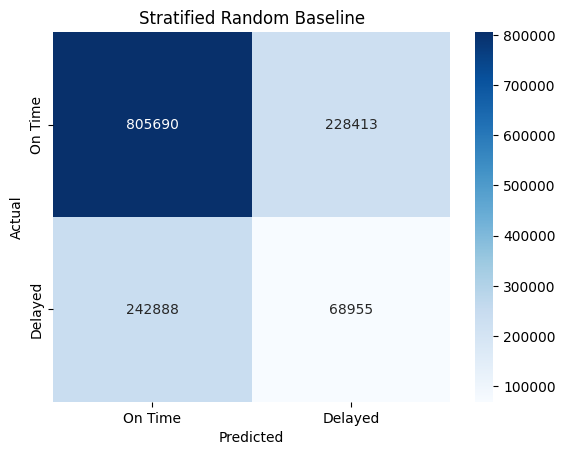

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["On Time", "Delayed"],
    yticklabels=["On Time", "Delayed"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Stratified Random Baseline")
plt.show()

In [ ]:
majority = DummyClassifier(strategy="most_frequent")
majority.fit(train[[TARGET]], y_train)

majority_pred = majority.predict(test[[TARGET]])

results = pd.DataFrame({
    "Model": ["Majority", "Stratified Random"],
    "Accuracy": [
        accuracy_score(y_test, majority_pred),
        accuracy_score(y_test, y_pred)
    ],
    "Precision": [
        precision_score(y_test, majority_pred, zero_division=0),
        precision_score(y_test, y_pred, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, majority_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0)
    ],
    "F1": [
        f1_score(y_test, majority_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0)
    ]
})

results.set_index("Model").round(4)

,Accuracy,Precision,Recall,F1
Model,,,,
Majority,0.7683,0.0000,0.0000,0.0000
Stratified Random,0.6498,0.2319,0.2211,0.2264


Split the data per month instead? So each month contributes train, validation, and testing data so we can predict more accurately?

In [ ]:
# Run the first loading cell first. New split, original train/test stay unchanged.
# 70% train, 15% validation, 15% test.

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

SEED = 42
TARGET = "ArrDel15"
assert flights[["Year", "Month", TARGET]].notna().all().all()
assert flights[TARGET].isin([0, 1]).all()

parts = {"train": [], "val": [], "test": []}
for _, idx in flights.groupby(["Year", "Month"], sort=True).indices.items():
    train_idx, heldout_idx = train_test_split(
        idx, test_size=0.30, random_state=SEED,
        stratify=flights.iloc[idx][TARGET]
    )
    val_idx, test_idx = train_test_split(
        heldout_idx, test_size=0.50, random_state=SEED,
        stratify=flights.iloc[heldout_idx][TARGET]
    )
    for name, positions in zip(parts, [train_idx, val_idx, test_idx]):
        parts[name].append(positions)

split_idx = {name: np.concatenate(chunks) for name, chunks in parts.items()}
all_idx = np.concatenate(list(split_idx.values()))
assert len(all_idx) == len(flights)
assert len(np.unique(all_idx)) == len(flights)  # Every row appears exactly once

train_monthly = flights.iloc[split_idx["train"]].copy()
val_monthly = flights.iloc[split_idx["val"]].copy()
test_monthly = flights.iloc[split_idx["test"]].copy()

monthly_counts = pd.DataFrame({
    "Train": train_monthly.groupby(["Year", "Month"]).size(),
    "Validation": val_monthly.groupby(["Year", "Month"]).size(),
    "Test": test_monthly.groupby(["Year", "Month"]).size()
})
assert monthly_counts.notna().all().all() and (monthly_counts > 0).all().all()
display(monthly_counts)
display(monthly_counts.sum().to_frame("Total flights"))



Train  Validation   Test
Year Month                           
2025 1      365588       78340  78341
     2      347533       74471  74472
     3      414610       88845  88846
     4      404411       86659  86660
     5      418301       89636  89637
     6      419630       89921  89921
     7      428967       91922  91922
     8      415613       89060  89060
     9      390829       83749  83750
     10     421099       90235  90236
     11     388707       83294  83295
     12     400346       85789  85789

,Total flights
Train,4815634
Validation,1031921
Test,1031929


In [12]:
# Dummy baselines on the NEW validation split (no test evaluation).
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix)

y_train_monthly = train_monthly[TARGET]
y_val_monthly = val_monthly[TARGET]
# Dummy models ignore features; use a constant instead of passing the target as X.
X_dummy_train = np.zeros((len(y_train_monthly), 1), dtype=np.uint8)
X_dummy_val = np.zeros((len(y_val_monthly), 1), dtype=np.uint8)

validation_results = []
validation_confusions = {}
def evaluate_validation(name, y_pred):
    validation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val_monthly, y_pred),
        "Precision": precision_score(y_val_monthly, y_pred, zero_division=0),
        "Recall": recall_score(y_val_monthly, y_pred, zero_division=0),
        "F1": f1_score(y_val_monthly, y_pred, zero_division=0)
    })
    validation_confusions[name] = confusion_matrix(y_val_monthly, y_pred)

for name, strategy in [("Majority", "most_frequent"),
                       ("Stratified random", "stratified")]:
    model = DummyClassifier(strategy=strategy, random_state=SEED)
    model.fit(X_dummy_train, y_train_monthly)
    scores = model.predict_proba(X_dummy_val)
    pred = model.classes_[scores.argmax(axis=1)]
    evaluate_validation(name, pred)

print(f"Train delayed: {y_train_monthly.mean():.2%}")
print(f"Validation delayed: {y_val_monthly.mean():.2%}")
summary = pd.DataFrame(validation_results).set_index("Model")
print("Monthly validation results")
display(summary[["Accuracy", "Precision", "Recall", "F1"]].round(4))
for name, cm in validation_confusions.items():
    print(name, "(rows=actual, columns=predicted; order: on-time, delayed)")
    print(cm)


Train delayed: 22.31%
Validation delayed: 22.31%
Monthly validation results


,Accuracy,Precision,Recall,F1
Model,,,,
Majority,0.7769,0.0000,0.0000,0.000
Stratified random,0.6532,0.2229,0.2231,0.223


Majority (rows=actual, columns=predicted; order: on-time, delayed)
[[801727      0]
 [230194      0]]
Stratified random (rows=actual, columns=predicted; order: on-time, delayed)
[[622649 179078]
 [178839  51355]]


In [13]:
# Logistic regression: 300k training flights, full validation, threshold 0.5.
import time
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

sample_n = min(300_000, len(train_monthly))
if sample_n < len(train_monthly):
    fit_positions, _ = train_test_split(
        np.arange(len(train_monthly)), train_size=sample_n, random_state=SEED,
        stratify=train_monthly["Month"].astype(str) + "_" + train_monthly[TARGET].astype(str)
    )
    fit_data = train_monthly.iloc[fit_positions]
else:
    fit_data = train_monthly

categorical = ["Month", "DayOfWeek", "Reporting_Airline", "Origin", "Dest"]
numeric = ["DayofMonth", "DepHour", "ArrHour", "CRSElapsedTime", "Distance"]
def make_features(data):
    X = data[["Month", "DayOfWeek", "Reporting_Airline", "Origin", "Dest",
              "DayofMonth", "CRSElapsedTime", "Distance"]].copy()
    X["DepHour"] = (data["CRSDepTime"] // 100) % 24
    X["ArrHour"] = (data["CRSArrTime"] // 100) % 24
    return X[categorical + numeric]

X_fit = make_features(fit_data)
X_val = make_features(val_monthly)
preprocess = ColumnTransformer([
    ("categories", OneHotEncoder(handle_unknown="ignore"), categorical),
    ("numbers", StandardScaler(), numeric)
])
lr = Pipeline([
    ("preprocess", preprocess),
    ("model", LogisticRegression(C=1.0, class_weight=None, max_iter=500,
                                 solver="lbfgs", random_state=SEED))
])
started = time.perf_counter()
lr.fit(X_fit, fit_data[TARGET])
fit_seconds = time.perf_counter() - started
val_scores_lr = lr.predict_proba(X_val)[:, 1]
val_pred_lr = (val_scores_lr >= 0.5).astype(int)
validation_results[:] = [r for r in validation_results if r["Model"] != "Logistic regression"]
evaluate_validation("Logistic regression", val_pred_lr)
print(f"Training rows: {len(X_fit):,}; validation rows: {len(X_val):,}")
print(f"Fit time: {fit_seconds:.1f}s; iterations: {lr.named_steps['model'].n_iter_}")
summary = pd.DataFrame(validation_results).set_index("Model")
print("Monthly validation results")
display(summary[["Accuracy", "Precision", "Recall", "F1"]].round(4))
print("Logistic regression confusion matrix (actual rows, predicted columns):")
print(validation_confusions["Logistic regression"])


Training rows: 300,000; validation rows: 1,031,921
Fit time: 4.8s; iterations: [129]
Monthly validation results


,Accuracy,Precision,Recall,F1
Model,,,,
Majority,0.7769,0.0000,0.0000,0.0000
Stratified random,0.6532,0.2229,0.2231,0.2230
Logistic regression,0.7776,0.5286,0.0278,0.0529


Logistic regression confusion matrix (actual rows, predicted columns):
[[796014   5713]
 [223789   6405]]
